# NB01 — Data cleaning (Week 1 workflow) and price preparation

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Produce one clean, documented 5-minute table for 2022–2023 that every later notebook reads:
site telemetry and weather (cleaned with the Week 1 workflow), the actual spot price for both years, the
"actual PV" column, and the import/export prices for the three tariffs (flat, ToU, wholesale passthrough).

**Inputs** (Google Drive folder `SOLA4237-A2`)
- `Data_QLD_Toowoomba - Warm Temperate_2022-2023_partial.csv` — course dataset
- `QLD_spot_price_2022/`, `QLD_spot_price_2023/` — AEMO aggregated price & demand, QLD1

**Outputs** (`outputs/`)
- `nb01_clean_2022_2023.csv` — clean 5-min table (210,240 rows)
- `nb01_cleaning_log.csv` — what was missing / flagged / filled per column (Appendix B)

**Method.** Week 1 workshop steps 1–7, using the workshop helper functions unchanged, plus Topic 4 slide 17 physical clipping.:
1. Columns that are blank **on purpose** (2022 commercial PV, 2023 measured PV, 2023 spot price) are **not** filled.
2. The outlier rule is **not** applied to the spot price — price spikes are real market outcomes, not sensor errors.

## Cell 0 — Settings
**Purpose:** make the notebook run both in Google Colab (Drive folder) and define all file paths in one place.
**Check:** the printout must list the data files; if a path is wrong, fix `BASE_DIR` here only.

In [1]:
# Cell 0 - Settings: runs in Google Colab
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)  # notebook sits in a subfolder -> use the parent
sys.path.append(BASE_DIR)                     # later notebooks: 'import bess_functions'

DATA_CSV   = os.path.join(BASE_DIR, 'Data_QLD_Toowoomba - Warm Temperate_2022-2023_partial.csv')
SPOT22_DIR = os.path.join(BASE_DIR, 'QLD_spot_price_2022')
SPOT23_DIR = os.path.join(BASE_DIR, 'QLD_spot_price_2023')
OUT_DIR    = os.path.join(BASE_DIR, 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)

print('Python', sys.version.split()[0], '| Colab:', IN_COLAB)
print('BASE_DIR:', BASE_DIR)
print(sorted(os.listdir(BASE_DIR)))

Mounted at /content/drive
Python 3.13.18 | Colab: True
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2
['Data_QLD_Toowoomba - Warm Temperate_2022-2023_partial.csv', 'Predispatch_2023', 'QLD_spot_price_2022', 'QLD_spot_price_2023', 'outputs']


## Cell 1 — Imports and constants
**Purpose:** collect every number used to build prices in one place, each with its source, so the report can cite them.

| Constant | Value | Source |
|---|---|---|
| Loss factor (MLF × DLF), Ergon East small customers 2023-24 | 1.062 | ACIL Allen final report, Table 5.18|
| Environmental (LRET + SRES) | $14.30/MWh | ACIL Allen, Table 5.6|
| Other market costs, Ergon | $4.61/MWh | ACIL Allen, Table 5.17 |
| Network ToU ERTOUET1 (NUOS, ex GST): evening 4–9 pm / day 9 am–4 pm / night 9 pm–9 am | 0.16734 / 0.03163 / 0.04947 $/kWh | Ergon Network Price List 2023-24, SACS Residential; windows: Tariff Guide §4.3.2|
| GST | 10 % on import components | modelling choice (AEMO and network prices are ex GST) |

Daily supply charges (incl. Ergon $1.20/day) are excluded from all tariffs (modelling choice; equal across tariffs).

In [2]:
# Cell 1 - Imports and price constants
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DT_H = 5 / 60                          # length of one interval in hours (kW -> kWh)

LOSS_FACTOR   = 1.062                  # MLF x DLF, Ergon East small customers 2023-24
ENV_AUD_KWH   = 14.30 / 1000           # LRET + SRES
OTHER_AUD_KWH = 4.61 / 1000            # NEM fees, ancillary, prudential (Ergon)
ENV_MKT_AUD_KWH = ENV_AUD_KWH + OTHER_AUD_KWH   # = 0.01891 $/kWh
GST = 1.10

NET_EVENING = 0.16734                  # 16:00-21:00  ERTOUET1 NUOS, $/kWh ex GST [R28]
NET_DAY     = 0.03163                  # 09:00-16:00
NET_NIGHT   = 0.04947                  # 21:00-09:00

MEASURED_COLS = ['irradiance_wm2', 'temperature_c', 'load_kw']   # measured in both years
print('env + market adder = %.5f $/kWh' % ENV_MKT_AUD_KWH)

env + market adder = 0.01891 $/kWh


## Cell 2 — Week 1 helper functions
**Purpose:** reuse the Week 1 workshop helpers **unchanged**: `reconstruct_expected_5min_timeline`, `flag_missing_columns`,
`fill_missing_same_timestamp`, `flag_and_fill_outliers`. `missing_ratio` and `outlier_ratio` were exercises in Week 1, so they are written here
following their docstrings.

In [3]:
# Cell 2 - Week 1 helper functions (copied from wk1_workshop.ipynb; docstrings shortened)

def reconstruct_expected_5min_timeline(df, datetime_col="datetime", freq="5min"):
    """Rebuild the regular 5-min timeline and reindex df onto it (missing intervals become NaN rows). [Week 1]"""
    out = df.copy()
    out[datetime_col] = pd.to_datetime(out[datetime_col], errors="coerce")
    out = out.dropna(subset=[datetime_col]).sort_values(datetime_col, kind="mergesort")
    if out.empty:
        return out
    out = out.drop_duplicates(subset=[datetime_col], keep="last")
    full_index = pd.date_range(out[datetime_col].min(), out[datetime_col].max(), freq=freq)
    out = out.set_index(datetime_col).reindex(full_index)
    out.index.name = datetime_col
    return out.reset_index()


def missing_ratio(df, col):
    """
    What it does: share of missing values in `col` relative to the number of rows.
    Input: df (DataFrame), col (str).  Output: float in [0, 1]; 0.0 if df has no rows.
    """
    if len(df) == 0:
        return 0.0
    return float(df[col].isna().sum() / len(df))


def flag_missing_columns(df, cols, suffix="_is_missing", as_int=False):
    """Add a True/False column f'{c}{suffix}' marking missing values of each c in cols. [Week 1]"""
    out = df.copy()
    for c in cols:
        if c in out.columns:
            flag = out[c].isna()
            out[f"{c}{suffix}"] = flag.astype(int) if as_int else flag
    return out


def fill_missing_same_timestamp(df, cols, datetime_col="datetime", time_format="%H:%M", mode="same_time_of_day"):
    """
    Fill missing values of `cols` using only the datetime column. [Week 1]
    same_time_of_day: forward-fill within each HH:MM bucket from earlier days.
    previous_observation: forward-fill chronologically.
    """
    out = df.copy()
    out["__pos__"] = range(len(out))
    out[datetime_col] = pd.to_datetime(out[datetime_col], errors="coerce")
    cols = [c for c in cols if c in out.columns]
    if not cols:
        return out.drop(columns="__pos__")
    if mode == "same_time_of_day":
        out = out.sort_values([datetime_col], kind="mergesort")
        out["__tod__"] = out[datetime_col].dt.strftime(time_format)
        for c in cols:
            out[c] = out.groupby("__tod__", dropna=False)[c].ffill()
        out = out.drop(columns="__tod__")
    elif mode == "previous_observation":
        out = out.sort_values([datetime_col], kind="mergesort")
        for c in cols:
            out[c] = out[c].ffill()
    else:
        raise ValueError("mode must be 'same_time_of_day' or 'previous_observation'")
    out = out.sort_values("__pos__").drop(columns="__pos__")
    return out


def outlier_ratio(df, col, n_std=10):
    """
    What it does: share of values outside mean +/- n_std * std (numeric coercion).
    Input: df, col, n_std.  Output: float in [0, 1]; 0.0 if df is empty or std is 0/NaN.
    """
    if len(df) == 0:
        return 0.0
    s = pd.to_numeric(df[col], errors="coerce")
    mean, std = s.mean(), s.std()
    if pd.isna(std) or std == 0:
        return 0.0
    mask = (s < mean - n_std * std) | (s > mean + n_std * std)
    return float(mask.sum() / len(df))


def flag_and_fill_outliers(df, cols, datetime_col="datetime", n_std=10, time_format="%H:%M",
                           mode="same_time_of_day", flag_suffix="_is_outlier"):
    """
    1) Flag values outside mean +/- n_std * std in f'{c}{flag_suffix}' and set them to NaN.
    2) Forward-fill (same_time_of_day or previous_observation), like the missing-value fill. [Week 1]
    """
    out = df.copy()
    out["__pos__"] = range(len(out))
    out[datetime_col] = pd.to_datetime(out[datetime_col], errors="coerce")
    cols = [c for c in cols if c in out.columns]
    if not cols:
        return out.drop(columns="__pos__")
    for c in cols:
        s = pd.to_numeric(out[c], errors="coerce")
        mean, std = s.mean(), s.std()
        if pd.isna(std) or std == 0:
            out[f"{c}{flag_suffix}"] = False
            continue
        mask_out = (s < mean - n_std * std) | (s > mean + n_std * std)
        out[f"{c}{flag_suffix}"] = mask_out.fillna(False)
        out.loc[mask_out, c] = pd.NA
    if mode == "same_time_of_day":
        out = out.sort_values([datetime_col], kind="mergesort")
        out["__tod__"] = out[datetime_col].dt.strftime(time_format)
        for c in cols:
            out[c] = out.groupby("__tod__", dropna=False)[c].ffill()
        out = out.drop(columns="__tod__")
    elif mode == "previous_observation":
        out = out.sort_values([datetime_col], kind="mergesort")
        for c in cols:
            out[c] = out[c].ffill()
    else:
        raise ValueError("mode must be 'same_time_of_day' or 'previous_observation'")
    out = out.sort_values("__pos__").drop(columns="__pos__")
    return out

print('Week 1 helpers loaded')

Week 1 helpers loaded


## Cell 3 — Step 1: load and inspect the raw data
**Purpose:** read the course CSV and rename columns to short names **with units** (coding convention).
**Check:** 210,240 rows × 11 columns, from 2022-01-01 00:00 to 2023-12-31 23:55.

In [4]:
# Cell 3 - Week 1 step 1: load and inspect
raw = pd.read_csv(DATA_CSV)
raw = raw.rename(columns={
    'timestamp': 'datetime',
    'irradiance_W/m^2': 'irradiance_wm2',
    'temperature_C': 'temperature_c',
    'solar_output_kW': 'pv_measured_kw',                      # measured PV (2022 only)
    'commercial_forecasted_solar_output_kW': 'pv_commercial_kw',  # commercial forecast (2023 only)
    'load_kW': 'load_kw',
    'spot_price_AUD/kWh': 'spot_aud_kwh',                      # 2022 only in the CSV
    'tariff_import_flat_AUD/kWh': 'import_flat_aud_kwh',
    'tariff_export_flat_AUD/kWh': 'export_flat_aud_kwh',
    'tariff_import_tou_AUD/kWh': 'import_tou_aud_kwh',
    'tariff_export_tou_AUD/kWh': 'export_tou_aud_kwh',
})
raw['datetime'] = pd.to_datetime(raw['datetime'])
print(raw.shape)
print(raw['datetime'].min(), '->', raw['datetime'].max())
print(raw.dtypes)
raw.describe().T.round(3)

(210240, 11)
2022-01-01 00:00:00 -> 2023-12-31 23:55:00
datetime               datetime64[ns]
irradiance_wm2                float64
temperature_c                 float64
pv_measured_kw                float64
pv_commercial_kw              float64
load_kw                       float64
spot_aud_kwh                  float64
import_flat_aud_kwh           float64
export_flat_aud_kwh           float64
import_tou_aud_kwh            float64
export_tou_aud_kwh            float64
dtype: object


,count,mean,min,25%,50%,75%,max,std
datetime,210240,2022-12-31 23:57:29.999999232,2022-01-01 00:00:00,2022-07-02 11:58:45,2022-12-31 23:57:30,2023-07-02 11:56:15,2023-12-31 23:55:00,NaN
irradiance_wm2,209192.0,214.726342,0.0,0.0,19.0,416.0,1141.0,290.645874
temperature_c,209192.0,17.205802,1.8,13.2,17.1,20.8,34.7,5.553
pv_measured_kw,104544.0,2.180863,0.0,0.0,0.2,4.03,14.55,3.027257
pv_commercial_kw,105120.0,2.425558,0.0,0.0,0.23,4.83,11.58,3.213514
load_kw,209192.0,1.279797,0.17,0.53,0.74,1.31,7.43,1.235003
spot_aud_kwh,105120.0,0.205142,-1.0,0.08849,0.137455,0.267128,15.5,0.595948
import_flat_aud_kwh,210240.0,0.3,0.3,0.3,0.3,0.3,0.3,0.0
export_flat_aud_kwh,210240.0,0.05,0.05,0.05,0.05,0.05,0.05,0.0
import_tou_aud_kwh,210240.0,0.241667,0.15,0.15,0.25,0.25,0.4,0.083749


## Cell 4 — Steps 2–3: columns kept and time zone
**Step 2 (remove irrelevant columns/rows):** all 11 columns are used later, so nothing is removed.
**Step 3 (convert to local time):** the timestamps are already local Queensland time (AEST, UTC+10). Queensland has no daylight saving and
AEMO also uses NEM time (AEST). **no conversion is needed**

**Timestamp convention:** each row is treated as the 5-minute interval *ending* at its label (AEMO `SETTLEMENTDATE` convention).
Nothing is shifted

In [5]:
# Cell 4 - Week 1 steps 2-3: nothing removed; timestamps already AEST
print('Columns kept:', list(raw.columns))
print('Timezone info on timestamps:', raw['datetime'].dt.tz)   # None = naive local time (AEST)

Columns kept: ['datetime', 'irradiance_wm2', 'temperature_c', 'pv_measured_kw', 'pv_commercial_kw', 'load_kw', 'spot_aud_kwh', 'import_flat_aud_kwh', 'export_flat_aud_kwh', 'import_tou_aud_kwh', 'export_tou_aud_kwh']
Timezone info on timestamps: None


## Cell 5 — Step 4a: reconstruct the expected 5-minute timeline
**Purpose:** make every missing interval an explicit row (Week 1 helper).
**Check:** no duplicates removed, no rows added (the dataset already has a complete timeline).

In [6]:
# Cell 5 - Week 1 step 4a: reconstruct the 5-min timeline
n_before = len(raw)
n_dup = raw['datetime'].duplicated().sum()
df = reconstruct_expected_5min_timeline(raw, datetime_col='datetime', freq='5min')
print('duplicates:', n_dup, '| rows before:', n_before, '| rows after:', len(df), '| rows added:', len(df) - n_before)
assert len(df) == 210240, 'unexpected number of 5-min intervals'

duplicates: 0 | rows before: 210240 | rows after: 210240 | rows added: 0


## Cell 6 — Step 4b: missing-value ratio per column and year
**Purpose:** separate *missing by design* from *real gaps*.
- Missing by design: `pv_measured_kw` in 2023, `pv_commercial_kw` in 2022, `spot_aud_kwh` in 2023 (filled with AEMO data in Cell 10).
- Real gaps: everything else.

In [7]:
# Cell 6 - Week 1 step 4b: missing ratio per column and year
df['year'] = df['datetime'].dt.year
value_cols = ['irradiance_wm2', 'temperature_c', 'pv_measured_kw', 'pv_commercial_kw', 'load_kw', 'spot_aud_kwh']
miss = pd.DataFrame({yr: {c: missing_ratio(df[df.year == yr], c) for c in value_cols} for yr in [2022, 2023]})
print((miss * 100).round(2).astype(str) + ' %')

# real gaps: blocks of consecutive missing load values
m = df['load_kw'].isna()
block_id = (m != m.shift()).cumsum()
blocks = df[m].groupby(block_id[m])['datetime'].agg(['first', 'size'])
print('\nNumber of gap blocks:', len(blocks), '| block length (intervals):', blocks['size'].min(), 'to', blocks['size'].max())
blocks.sort_values('size', ascending=False).head(5)

                     2022     2023
irradiance_wm2     0.55 %   0.45 %
temperature_c      0.55 %   0.45 %
pv_measured_kw     0.55 %  100.0 %
pv_commercial_kw  100.0 %    0.0 %
load_kw            0.55 %   0.45 %
spot_aud_kwh        0.0 %  100.0 %

Number of gap blocks: 24 | block length (intervals): 12 to 288


,first,size
load_kw,,
14,2022-10-07 23:10:00,288
2,2022-02-27 01:00:00,66
36,2023-08-08 18:50:00,66
48,2023-11-13 10:25:00,66
22,2022-12-28 06:15:00,65


## Cell 7 — Step 4c: flag and fill real gaps (same time of day)
**Purpose:** add `*_is_missing` flags, then fill with the Week 1 `same_time_of_day` mode (forward-fill from the same HH:MM on earlier days).

**Scoping:** the helper forward-fills the *whole* column, which would copy 2022 PV into the blank 2023 rows.
So the fill is applied to **year slices**: measured columns on the full table, `pv_measured_kw` on 2022 only, `pv_commercial_kw` on 2023 only.
Blank-by-design cells therefore stay blank.

In [8]:
# Cell 7 - Week 1 step 4c: flag missing values, then fill real gaps only
FLAG_COLS = MEASURED_COLS + ['pv_measured_kw', 'pv_commercial_kw']
df = flag_missing_columns(df, cols=FLAG_COLS)
# by-design blanks are not 'missing data' -> switch their flags off
df.loc[df.year == 2023, 'pv_measured_kw_is_missing'] = False
df.loc[df.year == 2022, 'pv_commercial_kw_is_missing'] = False

df = fill_missing_same_timestamp(df, cols=MEASURED_COLS, datetime_col='datetime', mode='same_time_of_day')
y22, y23 = df.year == 2022, df.year == 2023
df.loc[y22] = fill_missing_same_timestamp(df.loc[y22], cols=['pv_measured_kw'], datetime_col='datetime', mode='same_time_of_day')
df.loc[y23] = fill_missing_same_timestamp(df.loc[y23], cols=['pv_commercial_kw'], datetime_col='datetime', mode='same_time_of_day')

print('Remaining NaN after fill:')
print(pd.DataFrame({'2022': df[y22][value_cols].isna().sum(), '2023': df[y23][value_cols].isna().sum()}))

Remaining NaN after fill:
                    2022    2023
irradiance_wm2         0       0
temperature_c          0       0
pv_measured_kw         0  105120
pv_commercial_kw  105120       0
load_kw                0       0
spot_aud_kwh           0  105120


## Cell 8 — Step 5: outliers (mean ± 10σ), measured columns only
**Purpose:** flag and fill outliers with the Week 1 rule (`n_std=10`, same-time-of-day fill).

**Scoping:** not applied to `spot_aud_kwh`. prices are market outcomes, and the spikes are what a battery earns from.
PV columns handled per year. blank years are not filled.

In [9]:
# Cell 8 - Week 1 step 5: outlier ratio, flag and fill (measured columns only)
ratios = {c: outlier_ratio(df, c, n_std=10) for c in MEASURED_COLS}
ratios['pv_measured_kw (2022)'] = outlier_ratio(df[y22], 'pv_measured_kw', n_std=10)
ratios['pv_commercial_kw (2023)'] = outlier_ratio(df[y23], 'pv_commercial_kw', n_std=10)
ratios['spot_aud_kwh (2022, NOT cleaned)'] = outlier_ratio(df[y22], 'spot_aud_kwh', n_std=10)
print(pd.Series(ratios).map(lambda r: f'{r*100:.3f} %'))

df = flag_and_fill_outliers(df, cols=MEASURED_COLS, datetime_col='datetime', n_std=10)
df['pv_measured_kw_is_outlier'] = False          # pre-create so the slice results can be stored
df['pv_commercial_kw_is_outlier'] = False
df.loc[y22] = flag_and_fill_outliers(df.loc[y22], cols=['pv_measured_kw'], datetime_col='datetime', n_std=10)
df.loc[y23] = flag_and_fill_outliers(df.loc[y23], cols=['pv_commercial_kw'], datetime_col='datetime', n_std=10)
outlier_flags = [c for c in df.columns if c.endswith('_is_outlier')]
print('\nOutliers flagged:', df[outlier_flags].sum().to_dict())

irradiance_wm2                      0.000 %
temperature_c                       0.000 %
load_kw                             0.000 %
pv_measured_kw (2022)               0.000 %
pv_commercial_kw (2023)             0.000 %
spot_aud_kwh (2022, NOT cleaned)    0.228 %
dtype: object

Outliers flagged: {'irradiance_wm2_is_outlier': 0, 'temperature_c_is_outlier': 0, 'load_kw_is_outlier': 0, 'pv_measured_kw_is_outlier': 0, 'pv_commercial_kw_is_outlier': 0}


## Cell 9 — Physical boundary clipping (Topic 4 slide 17)
**Purpose:** irradiance, PV and load cannot be negative. Count negatives, then clip at 0.

In [10]:
# Cell 9 - physical clipping: irradiance, PV and load >= 0
clip_cols = ['irradiance_wm2', 'pv_measured_kw', 'pv_commercial_kw', 'load_kw']
n_neg = {c: int((df[c] < 0).sum()) for c in clip_cols}
for c in clip_cols:
    df[c] = df[c].clip(lower=0.0)
print('negative values clipped:', n_neg)

negative values clipped: {'irradiance_wm2': 0, 'pv_measured_kw': 0, 'pv_commercial_kw': 0, 'load_kw': 0}


## Cell 10 — AEMO spot prices: alignment check (2022) and 2023 merge
**Purpose:** fill the blank 2023 spot price with the **actual** AEMO RRP (used for settlement and the perfect-foresight runs).
- AEMO `RRP` is in $/MWh → divide by 1000 for $/kWh (Week 2 [R9]). `SETTLEMENTDATE` = end of the 5-min interval.
- **Check on 2022:** the CSV price should equal AEMO RRP on the **same** label (only the first row, 2022-01-01 00:00, is back-filled in the CSV).
- Each monthly AEMO file also contains 00:00 of the next month, so the Dec-2022 file supplies 2023-01-01 00:00.

In [11]:
# Cell 10 - AEMO prices: check alignment on 2022, merge actual 2023 prices
files = sorted(glob.glob(os.path.join(SPOT22_DIR, '*.csv'))) + sorted(glob.glob(os.path.join(SPOT23_DIR, '*.csv')))
aemo = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
aemo['SETTLEMENTDATE'] = pd.to_datetime(aemo['SETTLEMENTDATE'])
aemo = aemo[aemo['REGION'] == 'QLD1'].drop_duplicates('SETTLEMENTDATE').set_index('SETTLEMENTDATE').sort_index()
aemo_spot = aemo['RRP'] / 1000.0                      # $/MWh -> $/kWh
print('AEMO files:', len(files), '| rows:', len(aemo_spot), '|', aemo_spot.index.min(), '->', aemo_spot.index.max())

# alignment check on 2022 (same label vs shifted by 5 min)
csv22 = df.loc[y22].set_index('datetime')['spot_aud_kwh'].iloc[1:]       # skip back-filled first row
diff_same  = (csv22 - aemo_spot.reindex(csv22.index)).abs()
diff_shift = (csv22 - aemo_spot.reindex(csv22.index + pd.Timedelta(minutes=5)).values).abs()
print('mean |CSV - AEMO|, same label : %.6f $/kWh' % diff_same.mean())
print('mean |CSV - AEMO|, AEMO +5 min: %.6f $/kWh' % diff_shift.mean())
assert diff_same.max() < 1e-6, 'CSV 2022 price does not match AEMO on the same label'

# merge actual 2023 prices on the same label
df = df.set_index('datetime')
df.loc[df.year == 2023, 'spot_aud_kwh'] = aemo_spot.reindex(df.index[df.year == 2023]).values
df = df.reset_index()
print('2023 spot price missing after merge:', int(df.loc[df.year == 2023, 'spot_aud_kwh'].isna().sum()))

AEMO files: 24 | rows: 210240 | 2022-01-01 00:05:00 -> 2024-01-01 00:00:00
mean |CSV - AEMO|, same label : 0.000000 $/kWh
mean |CSV - AEMO|, AEMO +5 min: 0.039725 $/kWh
2023 spot price missing after merge: 0


## Cell 11 — Actual PV column and tariff prices
**Purpose:**
- `pv_actual_kw` = measured PV in 2022, commercial forecast in 2023 (the brief: treat the commercial forecast as the real 2023 measurement).
- Wholesale passthrough: **import = (spot × 1.062 + network ToU + 0.01891) × 1.10**, **export = spot**.
- Network windows: the dataset's own ToU column switches at the label (e.g. the 07:00 row is already shoulder),
  so the network window is classified by the label hour in the same way, for consistency.

In [12]:
# Cell 11 - actual PV and wholesale passthrough prices
df['pv_actual_kw'] = np.where(df.year == 2022, df['pv_measured_kw'], df['pv_commercial_kw'])

hour = df['datetime'].dt.hour
df['network_aud_kwh'] = np.select(
    [(hour >= 16) & (hour < 21), (hour >= 9) & (hour < 16)],
    [NET_EVENING, NET_DAY],
    default=NET_NIGHT)

df['import_wholesale_aud_kwh'] = (df['spot_aud_kwh'] * LOSS_FACTOR + df['network_aud_kwh'] + ENV_MKT_AUD_KWH) * GST
df['export_wholesale_aud_kwh'] = df['spot_aud_kwh']

summary = df.groupby('year')[['spot_aud_kwh', 'import_wholesale_aud_kwh', 'import_flat_aud_kwh', 'import_tou_aud_kwh']].mean()
print('Average prices ($/kWh, time-weighted):')
summary.round(4)

Average prices ($/kWh, time-weighted):


,spot_aud_kwh,import_wholesale_aud_kwh,import_flat_aud_kwh,import_tou_aud_kwh
year,,,,
2022,0.2051,0.3362,0.3,0.2417
2023,0.0907,0.2024,0.3,0.2417


## Cell 12 — Step 6–7 checks: totals and a visual check of the largest filled gap
**Purpose:** confirm the cleaned data look plausible.

      load_MWh  pv_actual_MWh  spot_mean_aud_kwh  spot_negative_share
year                                                                 
2022    11.197         19.089              0.205                0.045
2023    11.217         21.248              0.091                0.135

All checks passed: no NaN in used columns, no negative load/PV/irradiance.


/tmp/ipykernel_950/1031884534.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  energy = df.groupby('year').apply(lambda g: pd.Series({


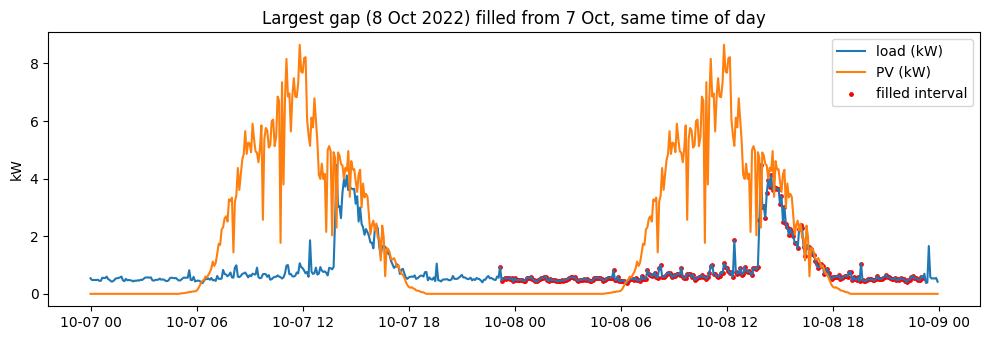

In [13]:
# Cell 12 - sanity checks and visual check
energy = df.groupby('year').apply(lambda g: pd.Series({
    'load_MWh': g['load_kw'].sum() * DT_H / 1000,
    'pv_actual_MWh': g['pv_actual_kw'].sum() * DT_H / 1000,
    'spot_mean_aud_kwh': g['spot_aud_kwh'].mean(),
    'spot_negative_share': (g['spot_aud_kwh'] < 0).mean(),
}))
print(energy.round(3))

used_cols = MEASURED_COLS + ['pv_actual_kw', 'spot_aud_kwh', 'import_wholesale_aud_kwh', 'export_wholesale_aud_kwh',
                             'import_flat_aud_kwh', 'export_flat_aud_kwh', 'import_tou_aud_kwh', 'export_tou_aud_kwh']
assert df[used_cols].isna().sum().sum() == 0, 'NaN left in a column used later'
assert (df[['load_kw', 'pv_actual_kw', 'irradiance_wm2']] >= 0).all().all()
print('\nAll checks passed: no NaN in used columns, no negative load/PV/irradiance.')

# visual check: the largest gap (8 Oct 2022) and the day before
win = df[(df.datetime >= '2022-10-07') & (df.datetime < '2022-10-09')]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(win.datetime, win.load_kw, label='load (kW)')
ax.plot(win.datetime, win.pv_actual_kw, label='PV (kW)')
filled = win[win.load_kw_is_missing]
ax.scatter(filled.datetime, filled.load_kw, s=6, color='red', label='filled interval')
ax.set_title('Largest gap (8 Oct 2022) filled from 7 Oct, same time of day')
ax.set_ylabel('kW'); ax.legend(); plt.tight_layout(); plt.show()

## Cell 13 — Save the clean table and the cleaning log
**Purpose:** later notebooks read only these files.

In [14]:
# Cell 13 - save outputs
keep = ['datetime', 'year', 'irradiance_wm2', 'temperature_c', 'pv_measured_kw', 'pv_commercial_kw', 'pv_actual_kw',
        'load_kw', 'spot_aud_kwh', 'network_aud_kwh',
        'import_flat_aud_kwh', 'export_flat_aud_kwh', 'import_tou_aud_kwh', 'export_tou_aud_kwh',
        'import_wholesale_aud_kwh', 'export_wholesale_aud_kwh'] + \
       [c for c in df.columns if c.endswith('_is_missing') or c.endswith('_is_outlier')]
clean = df[keep].copy()
clean_path = os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv')
clean.to_csv(clean_path, index=False)

log = pd.DataFrame({
    'missing_filled': {c: int(df[f'{c}_is_missing'].sum()) for c in FLAG_COLS},
    'missing_pct': {c: round(100 * df[f'{c}_is_missing'].mean(), 3) for c in FLAG_COLS},
    'outliers_filled': {c: int(df[f'{c}_is_outlier'].sum()) for c in FLAG_COLS},
    'negatives_clipped': {c: n_neg.get(c, 0) for c in FLAG_COLS},
})
log_path = os.path.join(OUT_DIR, 'nb01_cleaning_log.csv')
log.to_csv(log_path)
print('saved', clean_path, clean.shape)
print('saved', log_path)
log

saved /content/drive/MyDrive/SOLA4237-A2/outputs/nb01_clean_2022_2023.csv (210240, 26)
saved /content/drive/MyDrive/SOLA4237-A2/outputs/nb01_cleaning_log.csv


,missing_filled,missing_pct,outliers_filled,negatives_clipped
irradiance_wm2,1048,0.498,0,0
temperature_c,1048,0.498,0,0
load_kw,1048,0.498,0,0
pv_measured_kw,576,0.274,0,0
pv_commercial_kw,0,0.000,0,0


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai, 21 Nov 2026 |
| What AI did | Drafted this notebook from my notes (Week 1 steps, scoping decisions, price formula and constants I supplied/approved) |
| Example prompt | “write NB01, put it under 'Notebook' subfolder. i'll upload it on colab and run it there” |
| How I checked it | *(fill in)* e.g. ran it in Colab; compared totals with Notes D.3; checked the 2022 price alignment assert; looked at the filled-gap plot; checked that 2023 PV was not filled from 2022 |
| What I changed | *(fill in)* |